<a href="https://colab.research.google.com/github/Jucksun/gsp-csice-research/blob/main/labprojectcode.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install pygsp


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pygsp as pg


rng = np.random.default_rng(42)

# Load Minnesota road graph
G = pg.graphs.Minnesota()
N = G.N
S = G.L.toarray()
lam, U = np.linalg.eigh(S)

# Source GFT covariance matrix
rho = 0.25
C_hat_x = (1 - rho) * np.eye(N) + rho * np.ones((N, N))

gamma_true = rng.choice([-1, 1], size=N) * (1 + rng.uniform(-0.2, 0.2, size=N))
H = U @ np.diag(gamma_true) @ U.T

M = 50
sigma = 0.5
C_x = U @ C_hat_x @ U.T
m = 2000

# real x values
X_hat = rng.multivariate_normal(np.zeros(N), C_hat_x, size=M).T  # Shape: (N, M)
X = U @ X_hat

# From provided project, Omegas and ys (you can explain omega if u wanttt)
Omegas = [rng.choice(N, size=m, replace=False) for _ in range(M)]
ys = [
    (H @ X[:, i] + rng.normal(0, sigma, size=N))[Omegas[i]] for i in range(M)
]

print(C_x.shape)
print(H.shape)


(2642, 2642)
(2642, 2642)


In [ ]:
Y_tt = np.zeros((N, M))
for i in range(M):
    Y_tt[Omegas[i], i] = ys[i]

#  covariance from observations for y
Y_hat = U.T @ Y_tt
C_y_hat = (Y_hat @ Y_hat.T) / M

# Estimate channel and gamma abs, without signs for now.
var_y = np.diag(C_y_hat)
var_x = np.diag(C_hat_x)
gamma_abs = np.sqrt(np.maximum(0, var_y) / np.maximum(1e-6, var_x))

# doing the sign estimation
cross_y = C_y_hat[0, :]
cross_x = np.where(C_hat_x[0, :] == 0, 1e-6, C_hat_x[0, :])
gamma_signs = np.sign(cross_y / cross_x)
gamma_signs[gamma_signs == 0] = 1.0

# Applying signs to gamma here
gamma_est = gamma_abs * gamma_signs


H_est = U @ np.diag(gamma_est) @ U.T

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# signal reconstruction
C_x = U @ C_hat_x @ U.T
H_est = U @ np.diag(gamma_est) @ U.T

X_est = np.zeros_like(X)
X_oracle = np.zeros_like(X)

for i, (Omega, y) in enumerate(zip(Omegas, ys)):
    A = H_est[Omega, :]
    B = H[Omega, :]  # true channel, for comparison only

    m_i = len(y)

    M_e = A @ C_x @ A.T + sigma**2 * np.eye(m_i)
    K = C_x @ A.T @ np.linalg.solve(M_e, y)

    M_o = B @ C_x @ B.T + sigma**2 * np.eye(m_i)
    K_oracle = C_x @ B.T @ np.linalg.solve(M_o, y)

    X_est[:, i] = K
    X_oracle[:, i] = K_oracle

# reconstruction errors
err_x = np.linalg.norm(X_est-X, 'fro') / np.linalg.norm(X, 'fro')
err_x_oracle = np.linalg.norm(X_oracle-X, 'fro') / np.linalg.norm(X, 'fro')

print("signal error (estimated H):", err_x)
print("signal error (true H):", err_x_oracle)


signal error (estimated H): 1.5417426084977712
signal error (true H): 0.5774874762522055


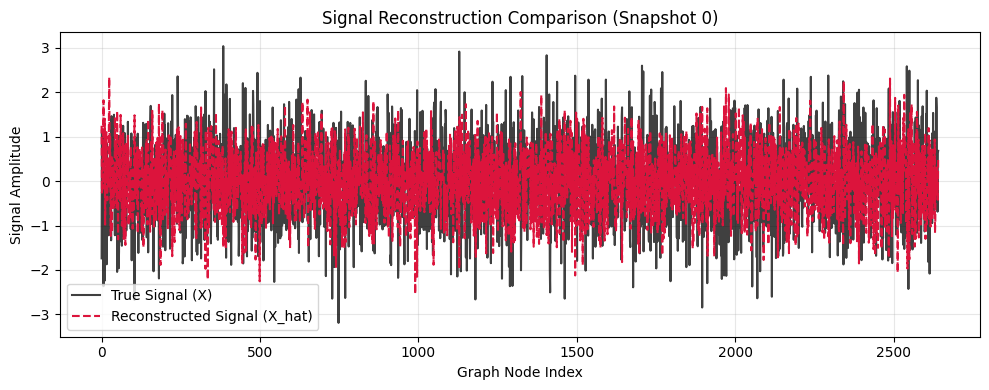

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

snapshot_idx = 0

plt.figure(figsize=(10, 4))
plt.plot(
    X[:, snapshot_idx],
    label="True Signal (X)",
    color="black",
    alpha=0.75,
    linewidth=1.5,
)
plt.plot(
    X_est[:, snapshot_idx],
    "--",
    label="Reconstructed Signal (X_hat)",
    color="crimson",
    linewidth=1.5,
)

plt.xlabel("Graph Node Index")
plt.ylabel("Signal Amplitude")
plt.title(f"Signal Reconstruction Comparison (Snapshot {snapshot_idx})")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()